# Assignment 9: Student Habits Analysis


## Part 1: Define the target

1. **Why is this a regression problem?**
   This is a regression problem because we are predicting a numerical exam score rather than a category.

2. **How is this different from the Class 2 classification problem?**
   In Class 2, we predicted whether a student's exam score would be high using a yes-or-no label. Here, we predict the student's numerical exam score.

3. **What information is lost when we convert exam score into only yes or no?**
   We lose the actual score, how much students' scores differ, and how far each score is from the cutoff. For example, scores of 80 and 100 both receive "yes," even though they differ by 20 points.

4. **What kind of output should a regression model produce?**
   A regression model should produce a numerical prediction for each student, such as an estimated exam score of 82.4, based on the student's input features.

## Load and preview the dataset

Read the CSV from this folder into `df`. Preserve the literal `None` as a prior-programming-experience category and treat blank cells as missing values.

In Google Colab, upload `class1_student_habits.csv` using the Files panel before running the notebook. For a local run, keep the CSV in the notebook's working folder.

In [70]:
import pandas as pd

df = pd.read_csv(
    "class1_student_habits.csv",
    keep_default_na=False,
    na_values=[""],
)
df.head()

,student_id,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,prior_programming_experience,study_group,commute_minutes,quiz_average,exam_score
0,S001,1.3,7.7,71.8,8,Strong,No,0,67.0,64.6
1,S002,9.4,6.6,74.2,14,None,Yes,52,74.8,81.5
2,S003,11.2,6.1,70.3,15,Some,No,7,99.1,92.0
3,S004,10.8,7.6,77.1,16,Strong,No,12,86.4,100.0
4,S005,8.0,5.6,89.7,15,None,Yes,12,75.7,68.5


## Part 2: Examine exam scores

Calculate the count, mean, median, standard deviation, minimum, and maximum of `exam_score`. Then create a histogram to examine the distribution of scores.

In [71]:
exam_scores = df["exam_score"]

summary_stats = pd.DataFrame({
    "Count": [exam_scores.count()],
    "Mean": [exam_scores.mean()],
    "Median": [exam_scores.median()],
    "Standard deviation": [exam_scores.std()],
    "Minimum": [exam_scores.min()],
    "Maximum": [exam_scores.max()],
})

display(summary_stats.round(2))

,Count,Mean,Median,Standard deviation,Minimum,Maximum
0,250,77.16,76.95,10.33,51.4,100.0


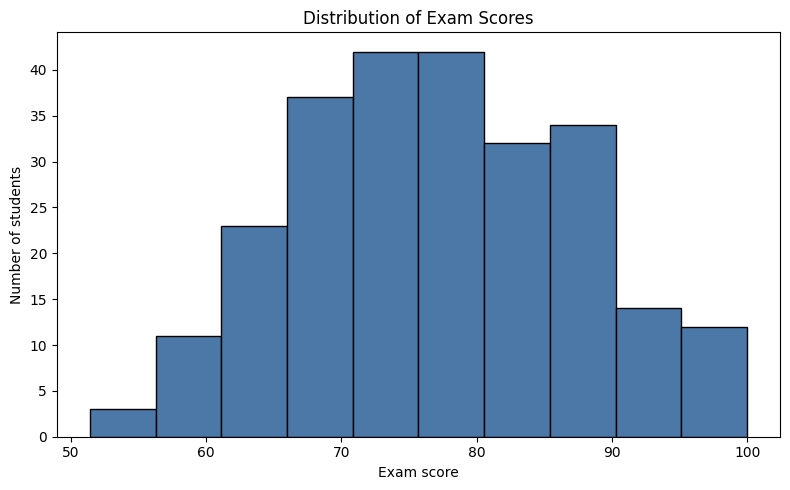

In [72]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    exam_scores.dropna(),
    bins=10,
    color="#4C78A8",
    edgecolor="black",
)

ax.set_title("Distribution of Exam Scores")
ax.set_xlabel("Exam score")
ax.set_ylabel("Number of students")

fig.tight_layout()
plt.show()

In [73]:
# Check the 1.5 x IQR rule used in the written answer below.
q1 = exam_scores.quantile(0.25)
q3 = exam_scores.quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

outlier_scores = exam_scores[
    (exam_scores < lower_fence) | (exam_scores > upper_fence)
]

print(f"Lower outlier boundary: {lower_fence:.2f}")
print(f"Upper outlier boundary: {upper_fence:.2f}")
print(f"Scores flagged as potential outliers: {len(outlier_scores)}")

Lower outlier boundary: 46.29
Upper outlier boundary: 108.19
Scores flagged as potential outliers: 0


### Part 2 questions

1. **Describe the distribution of exam scores.**
   Exam scores cluster around the middle, especially in the 70s and 80s, with fewer scores at either end. The distribution is roughly symmetric, with a mean of 77.16 and a median of 76.95.

2. **Are there unusually low or high values?**
   The lowest score is 51.4 and the highest is 100. Scores near these extremes are less common than scores around the middle. Using the common **1.5 × IQR rule**, scores below approximately **46.29** or above **108.19** would be flagged as potential outliers. All recorded scores fall within these boundaries, so none are flagged by this rule. This does not guarantee that every value is correct.

3. **Why is it useful to understand the target before trying to predict it?**
   Understanding the target helps us recognize typical scores, how much scores vary, and possible data problems. It also gives us context for judging whether the model's prediction errors are large or small.

## Part 3: Explore relationships

Investigate the relationship between `study_hours_per_week` and `exam_score` using a scatter plot and Pearson correlation. Use students with both measurements recorded.

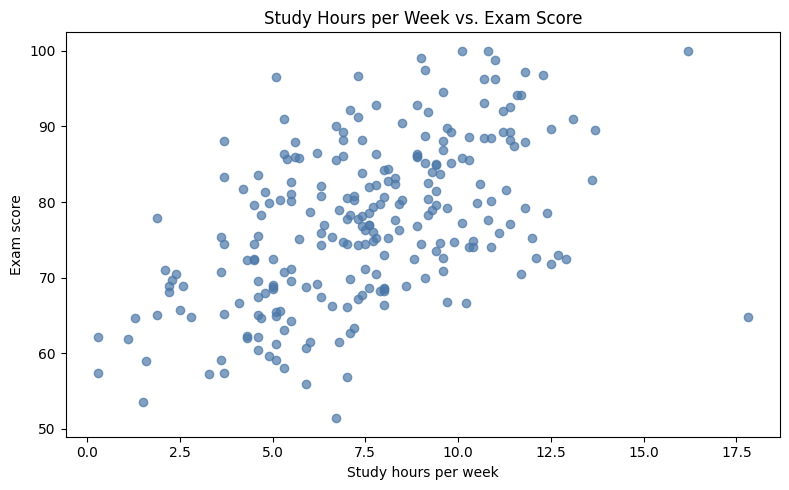

Students analyzed: 241
Pearson correlation: 0.516


In [74]:
import matplotlib.pyplot as plt

# Keep students who have both study hours and an exam score.
study_exam = df[
    ["study_hours_per_week", "exam_score"]
].dropna()

# Create the scatter plot.
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    study_exam["study_hours_per_week"],
    study_exam["exam_score"],
    color="#4C78A8",
    alpha=0.7,
)

ax.set_title("Study Hours per Week vs. Exam Score")
ax.set_xlabel("Study hours per week")
ax.set_ylabel("Exam score")

fig.tight_layout()
plt.show()

# Calculate the Pearson correlation.
correlation = study_exam["study_hours_per_week"].corr(
    study_exam["exam_score"],
    method="pearson",
)

print(f"Students analyzed: {len(study_exam)}")
print(f"Pearson correlation: {correlation:.3f}")

### Part 3 questions

1. **Does there appear to be a relationship?**
   Yes, there appears to be a relationship between weekly study hours and exam score, although there is considerable variation among students.

2. **Is the relationship positive or negative?**
   The relationship is positive: students who study more hours generally tend to have higher exam scores. The correlation of **0.516** indicates a moderate positive linear relationship. This association does not prove that studying additional hours causes a higher exam score.

3. **Does it appear approximately linear?**
   Yes, the overall pattern appears approximately linear because scores generally increase as study hours increase. However, the points are widely scattered around that trend.

4. **Are there students who do not follow the general pattern?**
   Yes. Some students study many hours but receive relatively low scores, while others study fewer hours and receive high scores. These examples show that study hours alone do not fully explain exam performance.

## Part 4: Choose features

Use the seven specified features to create `X`, and use `exam_score` as the numerical target `y`. Exclude `student_id`, `exam_score`, and `quiz_average` from the initial feature table.

In [75]:
# Select the seven features for the initial model.
feature_columns = [
    "study_hours_per_week",
    "sleep_hours_per_night",
    "attendance_rate",
    "practice_problems_per_week",
    "prior_programming_experience",
    "study_group",
    "commute_minutes",
]

# Create the feature table and target.
X = df[feature_columns].copy()
y = df["exam_score"].copy()

# Preview the features and target.
display(X.head())
display(y.head())

# Check their dimensions.
print(f"Feature table shape: {X.shape}")
print(f"Target shape: {y.shape}")

,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,prior_programming_experience,study_group,commute_minutes
0,1.3,7.7,71.8,8,Strong,No,0
1,9.4,6.6,74.2,14,None,Yes,52
2,11.2,6.1,70.3,15,Some,No,7
3,10.8,7.6,77.1,16,Strong,No,12
4,8.0,5.6,89.7,15,None,Yes,12


0     64.6
1     81.5
2     92.0
3    100.0
4     68.5
Name: exam_score, dtype: float64

Feature table shape: (250, 7)
Target shape: (250,)


## Part 5: Create training and test sets

Split the students into 80% training data and 20% test data using `random_state=42`. Keep each student's features paired with their exam score.

In [76]:
from sklearn.model_selection import train_test_split

# Split students into 80% training data and 20% test data.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

# Check the dimensions of each set.
print(f"Training features: {X_train.shape}")
print(f"Test features: {X_test.shape}")
print(f"Training targets: {y_train.shape}")
print(f"Test targets: {y_test.shape}")

Training features: (200, 7)
Test features: (50, 7)
Training targets: (200,)
Test targets: (50,)


### Part 5 questions

1. **What is the training set used for?**
   The training set is used to teach the model relationships between students' input features and their actual exam scores, so it can predict scores for other students.

2. **What is the test set used for?**
   The test set evaluates how well the trained model predicts exam scores for students it did not encounter during training.

3. **Why should the model not be trained using the test set?**
   Training on the test set would allow those students' scores to influence the model. Its test performance could then look better than its performance on new students because the evaluation data would no longer be independent of training.

4. **Why should different experiments use the same split when we want to compare them fairly?**
   Using the same split gives each model the same training students and evaluates it on the same test students. This makes it easier to attribute performance differences to changes in the model or features, rather than one experiment receiving an easier group of students.

## Part 6: Preprocess the features

For numerical features, fill missing values with training medians and then apply `StandardScaler`. For categorical features, fill missing values with the most frequent training categories and then apply one-hot encoding. Learn preprocessing rules from the training set and apply the same rules to the test set.

In [77]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Separate the features by type.
numeric_features = [
    "study_hours_per_week",
    "sleep_hours_per_night",
    "attendance_rate",
    "practice_problems_per_week",
    "commute_minutes",
]

categorical_features = [
    "prior_programming_experience",
    "study_group",
]

# Numerical features: fill missing values, then scale.
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# Categorical features: fill missing values, then encode.
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False,
    )),
])

# Apply the appropriate pipeline to each group of columns.
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

# Learn preprocessing rules from training data and apply them.
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same learned rules to test data.
X_test_processed = preprocessor.transform(X_test)

print(f"Processed training features: {X_train_processed.shape}")
print(f"Processed test features: {X_test_processed.shape}")

Processed training features: (200, 10)
Processed test features: (50, 10)


### Part 6 questions

1. **Why do we handle numerical and categorical variables differently?**
   Numerical variables represent measurable quantities, so we can fill missing values and scale them. Categorical variables represent groups or labels, so we need to encode them numerically before our regression model can use them. The encoding should avoid introducing misleading numerical distances between categories.

2. **What does StandardScaler do?**
   `StandardScaler` subtracts each numerical column's training mean and divides by its training standard deviation. This gives nonconstant training columns a mean of approximately zero and a standard deviation of one, putting features with different units on comparable scales. This helps models that are sensitive to feature scale.

3. **What does one-hot encoding do?**
   One-hot encoding creates a separate numerical indicator column for each category. A value of **1** means the student belongs to that category, and **0** means they do not. This lets the model use categorical information without assigning arbitrary numerical distances between categories.

4. **Why should preprocessing be learned from the training data rather than the entire dataset?**
   Learning preprocessing from the entire dataset would allow test information to influence replacement values, scaling statistics, and category mappings. This creates data leakage and can make performance appear better than it would on new data. We should learn the rules from the training set and apply those same rules to the test set.

## Part 7: Establish a regression baseline

Calculate the mean exam score using only the training data. Predict this same mean for every test student, then evaluate the baseline using MAE, MSE, RMSE, and R squared. Keep these results for comparison with the regression model.

In [78]:
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

# Calculate the mean using only the training scores.
training_mean = y_train.mean()

# Predict that same mean for every test student.
baseline_predictions = np.full(len(y_test), training_mean)

# Evaluate the predictions against the actual test scores.
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_mse = mean_squared_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(baseline_mse)
baseline_r2 = r2_score(y_test, baseline_predictions)

# Display the baseline prediction and evaluation results.
print(f"Training mean exam score: {training_mean:.2f}")
print(f"MAE: {baseline_mae:.2f}")
print(f"MSE: {baseline_mse:.2f}")
print(f"RMSE: {baseline_rmse:.2f}")
print(f"R squared: {baseline_r2:.6f}")

Training mean exam score: 77.73
MAE: 7.66
MSE: 96.08
RMSE: 9.80
R squared: -0.091077


### Part 7 questions

**Why is this useful?**

The baseline is useful because it shows how well we can predict exam scores by giving every student the training-set average. It provides a benchmark for evaluating the regression model. If the model produces smaller prediction errors than the baseline, that demonstrates that learning from students' features adds useful predictive information.

## Part 8: Train a linear regression model

Combine the preprocessor from Part 6 with `LinearRegression` in one pipeline. Fit the pipeline using the training features and exam scores, predict scores for the test students, and preview actual scores alongside predictions.

In [79]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

# Combine preprocessing and linear regression.
regression_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression()),
])

# Learn preprocessing rules and model weights from training data.
regression_pipeline.fit(X_train, y_train)

# Predict exam scores for the test students.
test_predictions = regression_pipeline.predict(X_test)

# Preview actual scores alongside predictions.
prediction_preview = pd.DataFrame({
    "Actual exam score": y_test,
    "Predicted exam score": test_predictions,
})

display(prediction_preview.head().round(2))

,Actual exam score,Predicted exam score
142,72.5,78.10
6,68.0,68.38
97,78.3,81.98
60,84.0,86.97
112,69.0,67.19


### Part 8 questions

1. **What does `.fit()` do?**
   `.fit()` trains the model using the training features and their actual exam scores. In our pipeline, it first learns the preprocessing rules, then learns the regression weights and intercept that minimize the total squared training error.

2. **What does `.predict()` do?**
   `.predict()` uses the trained pipeline to process the supplied features and calculate a predicted exam score for each student. It applies the preprocessing rules and regression weights learned during training.

3. **Why can the predicted exam score contain decimals even if the original scores are whole numbers?**
   Linear regression estimates a continuous numerical value. Its learned weights and intercept can contain decimals, so their combination can produce a prediction such as 82.4 even when all training scores are whole numbers. The model does not automatically round predictions to integers.

## Part 9: Evaluate prediction error

Evaluate the Linear Regression predictions using MAE, MSE, RMSE, and R squared. Compare these metrics with the training-mean baseline on the same test students. Lower MAE, MSE, and RMSE and higher R squared indicate better performance.

In [80]:
# Evaluate the Linear Regression predictions.
model_mae = mean_absolute_error(y_test, test_predictions)
model_mse = mean_squared_error(y_test, test_predictions)
model_rmse = np.sqrt(model_mse)
model_r2 = r2_score(y_test, test_predictions)

# Compare the baseline and model on the same test students.
model_comparison = pd.DataFrame({
    "Model": ["Mean baseline", "Linear Regression"],
    "MAE": [baseline_mae, model_mae],
    "MSE": [baseline_mse, model_mse],
    "RMSE": [baseline_rmse, model_rmse],
    "R squared": [baseline_r2, model_r2],
})

# Display the results with appropriate decimal precision.
display(model_comparison.round({
    "MAE": 2,
    "MSE": 2,
    "RMSE": 2,
    "R squared": 6,
}))

,Model,MAE,MSE,RMSE,R squared
0,Mean baseline,7.66,96.08,9.80,-0.091077
1,Linear Regression,5.77,69.70,8.35,0.208510


### Part 9 questions

1. **Which metric is easiest to explain in terms of exam-score points?**
   MAE is the easiest to explain because it directly reports the average absolute difference between predicted and actual scores. Our MAE of 5.77 means the model's predictions differ from actual scores by about 5.77 exam-score points on average. Individual errors can be smaller or larger; this does not mean every prediction is within 5.77 points.

2. **Why does MSE penalize large errors more heavily than MAE?**
   MSE squares each error before averaging, so large mistakes contribute disproportionately more to the result. MAE uses the absolute error without squaring it. For example, a 2-point error contributes 4 to MSE's calculation, while a 10-point error contributes 100. The larger error contributes 25 times as much to MSE's calculation, compared with 5 times as much to MAE's calculation.

3. **Why might RMSE be easier to interpret than MSE?**
   RMSE takes the square root of MSE, returning the result to exam-score points. Our MSE is 69.70 points squared, while our RMSE is about 8.35 exam-score points. The original units make RMSE easier to connect to the scores we are predicting. When calculated from the same prediction errors, RMSE is always at least as large as MAE. Our RMSE of 8.35 is noticeably higher than our MAE of 5.77 because larger errors receive more influence in RMSE. The large error for S174 contributes substantially to this difference.

4. **Did Linear Regression outperform the mean baseline?**
   Yes, Linear Regression performed better on this test set. MAE decreased from 7.66 to 5.77 points, reducing average absolute error by approximately 1.89 points. RMSE also decreased from 9.80 to 8.35 points. These improvements show that using student features provided more useful predictions than assigning everyone the training-set average. MSE decreased and R squared increased as well, so all four metrics support that conclusion. This is an improvement in overall performance; individual students can still have large prediction errors.

5. **What does your R squared value tell you?**
   Our R squared of approximately 0.209 means the model reduced total squared prediction error by about 20.9% compared with predicting the test-set mean for everyone. This shows useful but modest predictive performance, with substantial score variation still unaccounted for. This can also be described as the model accounting for about 20.9% of the variation in test scores.

   For R squared specifically, the reference uses the test-set mean. Our assignment baseline predicts the training-set mean. The test mean is used only for evaluation; it does not train our model or determine its predictions.

   The baseline's R squared is approximately **−0.091** because it predicts the training mean of **77.73**, while the test mean is **74.89**. R squared compares predictions with the test-set mean, so our training-mean baseline performs slightly worse than that reference.

   Linear Regression's R squared of **0.209** represents a **20.9%** reduction in squared error relative to predicting the test mean. Compared with our actual training-mean baseline, MSE decreased from **96.08 to 69.70**—a reduction of approximately **27.5%**. Both percentages are correct because they use different reference predictions.

## Part 10: Actual vs. predicted plot

Plot actual test scores on the horizontal axis and predicted scores on the vertical axis. The diagonal reference line shows where actual and predicted scores are equal.

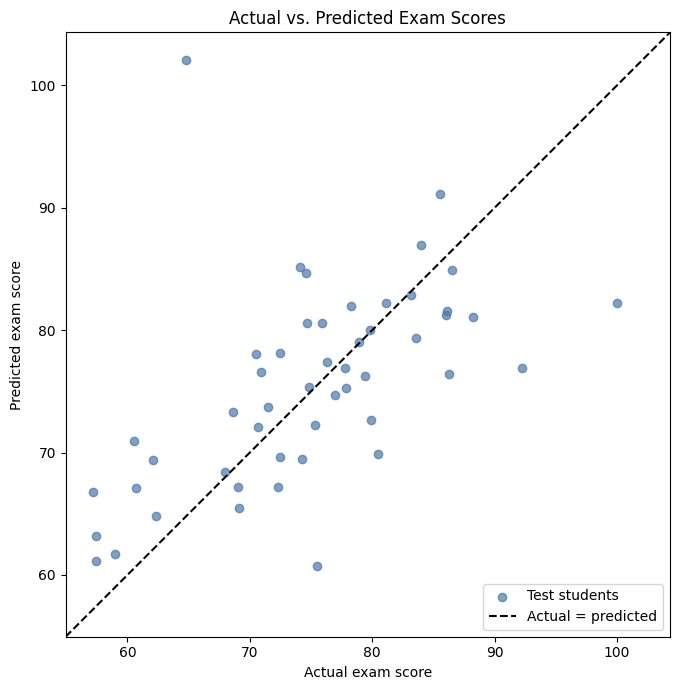

In [81]:
import matplotlib.pyplot as plt

# Find a shared plotting range for actual and predicted scores.
score_min = min(y_test.min(), test_predictions.min())
score_max = max(y_test.max(), test_predictions.max())

# Add some space around the smallest and largest values.
padding = (score_max - score_min) * 0.05
lower_limit = score_min - padding
upper_limit = score_max + padding

# Plot one point for each test student.
fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(
    y_test,
    test_predictions,
    color="#4C78A8",
    alpha=0.7,
    label="Test students",
)

# Add the reference line for perfect predictions.
ax.plot(
    [lower_limit, upper_limit],
    [lower_limit, upper_limit],
    color="black",
    linestyle="--",
    label="Actual = predicted",
)

ax.set_title("Actual vs. Predicted Exam Scores")
ax.set_xlabel("Actual exam score")
ax.set_ylabel("Predicted exam score")

ax.set_xlim(lower_limit, upper_limit)
ax.set_ylim(lower_limit, upper_limit)
ax.set_aspect("equal", adjustable="box")

ax.legend()
fig.tight_layout()
plt.show()

### Part 10 questions

1. **What would a perfect model look like on this graph?**
   Every point would lie exactly on the diagonal line where actual score equals predicted score. For example, a student who scored 80 would also have a predicted score of 80. The points must follow this particular diagonal for the predictions to be perfect.

2. **Are most points close to the diagonal?**
   Most points appear fairly close to the diagonal, showing that many predictions are reasonably close to the actual scores. However, there is noticeable scatter and a few large errors.

3. **Where does the model appear to make larger errors?**
   Some larger errors occur toward the lower and higher ends of the actual scores. For example, one student scored approximately 65, but the model predicted approximately 102. Another scored 100, but the model predicted approximately 82. These points are far from the diagonal, showing substantial overprediction and underprediction.

   Distance from the diagonal indicates prediction error. A point near the edge of the graph can still be accurate if it sits close to that line.

## Part 11: Residual analysis

Calculate each test student's residual as actual score minus predicted score. Plot predicted scores on the horizontal axis and residuals on the vertical axis, with a horizontal reference line at zero.

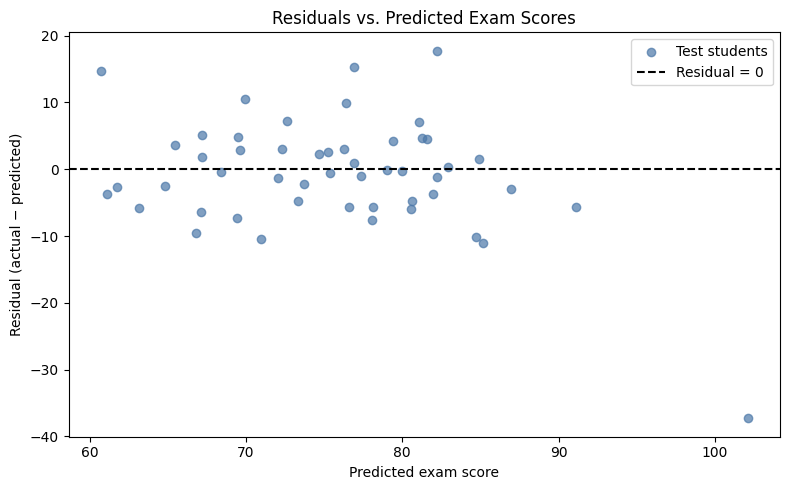

In [82]:
import matplotlib.pyplot as plt

# Calculate the residual for each test student.
residuals = y_test - test_predictions

# Create the residual scatter plot.
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    test_predictions,
    residuals,
    color="#4C78A8",
    alpha=0.7,
    label="Test students",
)

# Add a reference line for perfect predictions.
ax.axhline(
    y=0,
    color="black",
    linestyle="--",
    label="Residual = 0",
)

# Add a title and axis labels.
ax.set_title("Residuals vs. Predicted Exam Scores")
ax.set_xlabel("Predicted exam score")
ax.set_ylabel("Residual (actual − predicted)")

ax.legend()
fig.tight_layout()
plt.show()

### Part 11 questions

1. **What does a positive residual mean?**
   The actual score was higher than the predicted score, so the model underpredicted.

2. **What does a negative residual mean?**
   The predicted score was higher than the actual score, so the model overpredicted.

3. **What does a residual close to zero mean?**
   The predicted score was close to the actual score, so the prediction error was small.

4. **Do you see any pattern in the residual plot?**
   Most residuals are scattered above and below zero, with no obvious curved pattern in the main group of points. At higher predicted scores, several residuals are negative, including one large residual of approximately −37 points. This suggests possible overprediction at the high end, although there are relatively few students in that range, so the evidence for a systematic pattern is limited.

## Part 12: Find the largest errors

Calculate absolute prediction error as the absolute value of actual score minus predicted score. Display the ten test students with the largest errors, including their original input features. Student IDs identify the records and are not used as model inputs.

In [83]:
# Keep the original features and identify each test student.
error_results = X_test.copy()
error_results.insert(
    0, "student_id", df.loc[X_test.index, "student_id"]
)

# Add actual scores, predictions, and errors.
error_results["actual_exam_score"] = y_test
error_results["predicted_exam_score"] = test_predictions
error_results["residual"] = y_test - test_predictions
error_results["absolute_error"] = error_results["residual"].abs()

# Find the ten largest absolute errors.
largest_errors = error_results.sort_values(
    "absolute_error",
    ascending=False,
).head(10)

# Put the prediction results before the input features.
display_columns = [
    "student_id",
    "actual_exam_score",
    "predicted_exam_score",
    "residual",
    "absolute_error",
] + feature_columns

display(largest_errors[display_columns].round(2))

,student_id,actual_exam_score,predicted_exam_score,residual,absolute_error,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,prior_programming_experience,study_group,commute_minutes
173,S174,64.8,102.09,-37.29,37.29,17.8,6.9,98.1,0,Strong,Yes,36
108,S109,100.0,82.25,17.75,17.75,10.1,7.3,91.6,25,None,Yes,0
19,S020,92.2,76.93,15.27,15.27,7.1,NaN,90.0,14,Some,Yes,24
69,S070,75.5,60.72,14.78,14.78,4.6,7.4,64.3,9,None,Yes,30
240,S241,74.1,85.16,-11.06,11.06,10.4,6.6,91.2,20,Some,No,0
196,S197,80.5,69.91,10.59,10.59,7.0,6.3,98.3,3,None,No,39
15,S016,60.5,70.98,-10.48,10.48,4.6,6.5,88.0,0,Strong,Yes,15
222,S223,74.6,84.70,-10.10,10.10,9.5,5.8,70.9,22,Strong,No,27
67,S068,86.3,76.42,9.88,9.88,5.3,6.2,98.2,22,Some,No,16
159,S160,57.2,66.77,-9.57,9.57,3.3,7.4,72.0,0,Strong,No,30


### Investigate two large-error cases

Select the largest overprediction and largest underprediction among the ten cases. Compare their numerical features with training-set medians to give context to the observations.

In [84]:
# The table is already sorted by absolute error.
# Select its first overprediction and first underprediction.
overprediction_case = largest_errors[
    largest_errors["residual"] < 0
].iloc[0]

underprediction_case = largest_errors[
    largest_errors["residual"] > 0
].iloc[0]

# Compare the cases with typical training values.
case_feature_comparison = pd.DataFrame({
    "Training median": X_train[numeric_features].median(),
    "Overprediction case":
        overprediction_case[numeric_features].astype(float),
    "Underprediction case":
        underprediction_case[numeric_features].astype(float),
})

display(case_feature_comparison.round(2))

,Training median,Overprediction case,Underprediction case
study_hours_per_week,7.60,17.8,10.1
sleep_hours_per_night,7.00,6.9,7.3
attendance_rate,85.75,98.1,91.6
practice_problems_per_week,16.50,0.0,25.0
commute_minutes,23.50,36.0,0.0


### Case discussions

**Case 1: S174 — Overprediction**

The data show that the model predicted **102.09**, while the student's actual score was **64.80**, giving a residual of **−37.29**. The student studied **17.8 hours per week** and had **98.1% attendance**, both above the training medians of **7.6 hours** and **85.75%**. However, the student completed **zero practice problems**, compared with a training median of **16.5**. One hypothesis is that the relationship between study hours and exam performance depends on how students practice, and the additive linear model may not capture that interaction. These observations do not establish why this student scored lower than predicted.

**Case 2: S109 — Underprediction**

The data show that the model predicted **82.25**, while the student's actual score was **100**, giving a residual of **+17.75**. The student studied **10.1 hours per week**, had **91.6% attendance**, and completed **25 practice problems per week**, all above the corresponding training medians. The student also reported **no prior programming experience** and participated in a **study group**. One hypothesis is that unrecorded factors, such as study effectiveness or understanding of the exam material, helped this student perform better than expected. The available data do not establish the cause of the underprediction.

### S174 sensitivity check

S174 contributes approximately **39.9%** of the model's total squared test error. The prediction of **102.09** also exceeds the highest observed exam score of **100**; Linear Regression is not constrained to the observed score range.

As a diagnostic sensitivity check, excluding S174 from evaluation reduces MAE from **5.77 to 5.13** and RMSE from **8.35 to 6.54**. This shows how strongly one large error influences the metrics. These are results for a different evaluation subset, so the full **50-student** test results remain our main evaluation.

In [85]:
# Measure S174's contribution to total squared test error.
s174_squared_error = error_results.loc[
    error_results["student_id"] == "S174", "residual"
].pow(2).sum()

total_squared_error = error_results["residual"].pow(2).sum()

print(
    f"S174's share of squared error: "
    f"{100 * s174_squared_error / total_squared_error:.1f}%"
)

# Diagnostic evaluation on the remaining 49 test students.
other_students = error_results[
    error_results["student_id"] != "S174"
]

other_mae = mean_absolute_error(
    other_students["actual_exam_score"],
    other_students["predicted_exam_score"],
)

other_rmse = np.sqrt(mean_squared_error(
    other_students["actual_exam_score"],
    other_students["predicted_exam_score"],
))

print(f"MAE excluding S174: {other_mae:.2f}")
print(f"RMSE excluding S174: {other_rmse:.2f}")

S174's share of squared error: 39.9%
MAE excluding S174: 5.13
RMSE excluding S174: 6.54


### Inspect zero-practice observations

Display the zero-practice students in the original test set and the contrasting S045 record from the dataset.

In [86]:
# Inspect the three zero-practice test students.
zero_practice_test = error_results.loc[
    error_results["practice_problems_per_week"] == 0
]

display(zero_practice_test[[
    "student_id",
    "practice_problems_per_week",
    "actual_exam_score",
    "predicted_exam_score",
    "residual",
    "absolute_error",
]].round(2))

# Show a contrasting zero-practice student from the full dataset.
display(df.loc[
    df["student_id"] == "S045",
    ["student_id", "practice_problems_per_week", "exam_score"],
])

,student_id,practice_problems_per_week,actual_exam_score,predicted_exam_score,residual,absolute_error
15,S016,0,60.5,70.98,-10.48,10.48
159,S160,0,57.2,66.77,-9.57,9.57
173,S174,0,64.8,102.09,-37.29,37.29


,student_id,practice_problems_per_week,exam_score
44,S045,0,88.7


**What the data show:** The three zero-practice students in the test set—**S174, S016, and S160**—were all overpredicted and appeared among the ten largest errors. However, another zero-practice student, **S045**, scored **88.7**, so zero practice does not consistently imply a low score.

**Interpretation:** This suggests a pattern worth investigating. These observations do not establish the cause of the errors.

## Part 13: Examine the linear regression coefficients

Extract each transformed feature name and its matching coefficient from the fitted pipeline. Numerical coefficients apply to standardized feature values. For categorical features, compare coefficients between categories of the same feature.

In [87]:
# Retrieve the fitted preprocessing and regression steps.
fitted_preprocessor = regression_pipeline.named_steps["preprocessor"]
fitted_regressor = regression_pipeline.named_steps["regressor"]

# Get the transformed feature names and their matching coefficients.
transformed_feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = fitted_regressor.coef_

# Pair each transformed feature with its coefficient.
coefficient_table = pd.DataFrame({
    "Transformed feature name": transformed_feature_names,
    "Coefficient": coefficients,
})

display(coefficient_table.round(3))

,Transformed feature name,Coefficient
0,numeric__study_hours_per_week,5.933
1,numeric__sleep_hours_per_night,1.329
2,numeric__attendance_rate,1.976
3,numeric__practice_problems_per_week,3.169
4,numeric__commute_minutes,0.528
5,categorical__prior_programming_experience_None,-4.867
6,categorical__prior_programming_experience_Some,-0.192
7,categorical__prior_programming_experience_Strong,5.060
8,categorical__study_group_No,0.120
9,categorical__study_group_Yes,-0.120


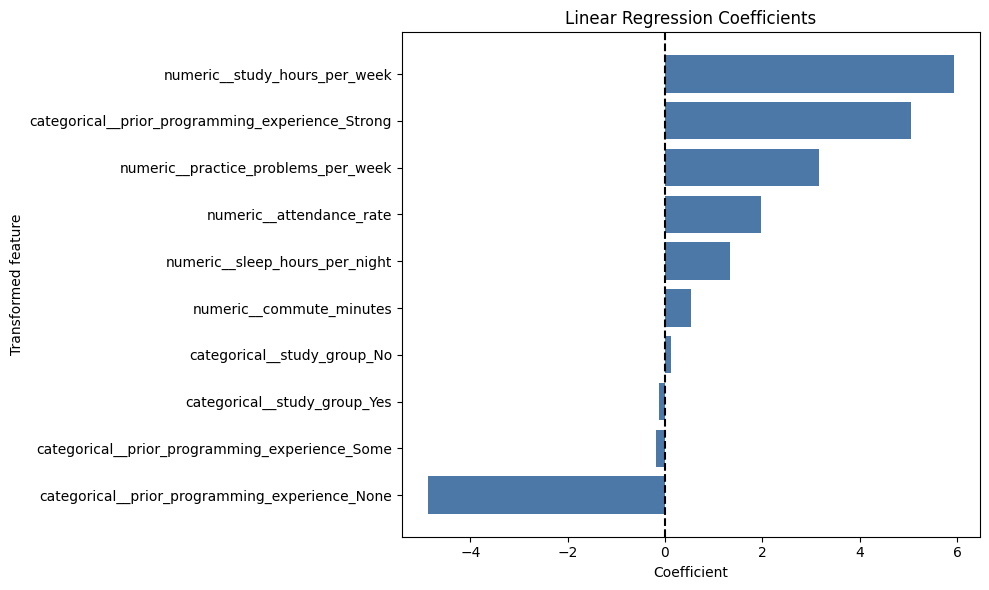

In [88]:
import matplotlib.pyplot as plt

# Sort the coefficients to make the chart easier to read.
coefficient_plot = coefficient_table.sort_values("Coefficient")

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    coefficient_plot["Transformed feature name"],
    coefficient_plot["Coefficient"],
    color="#4C78A8",
)

# Separate positive and negative coefficients visually.
ax.axvline(
    x=0,
    color="black",
    linestyle="--",
)

ax.set_title("Linear Regression Coefficients")
ax.set_xlabel("Coefficient")
ax.set_ylabel("Transformed feature")

fig.tight_layout()
plt.show()

### Part 13 questions

1. **Which features have positive coefficients?**
   The positive coefficients are study hours per week, strong prior programming experience, practice problems per week, attendance rate, sleep hours per night, commute minutes, and the "No" category for study group.

2. **Which features have negative coefficients?**
   The negative coefficients are the "Yes" category for study group, "Some" prior programming experience, and "None" prior programming experience.

3. **Which coefficients have relatively large magnitudes?**
   The largest absolute coefficient values are study hours per week (**+5.933**), strong prior programming experience (**+5.060**), no prior programming experience (**−4.867**), and practice problems per week (**+3.169**). A negative coefficient can have a large magnitude because magnitude measures distance from zero.

4. **What does a positive coefficient mean in this fitted model?**
   A positive coefficient means the fitted model associates a higher transformed feature value with a higher predicted exam score, holding its other modeled features fixed. This does not prove that changing the feature itself causes the actual exam score to increase. For example, the study-hours coefficient of approximately **+5.93** means a one-standard-deviation increase in study hours raises the model's prediction by about **5.93 points**, with the other inputs held fixed.

   For categorical features, interpret differences between categories of the same feature. A category's positive sign alone does not tell us its effect compared with every other category.

Because our encoding includes every category along with an intercept, category differences are more meaningful than individual category coefficients. For example, Strong prior programming experience has a coefficient of approximately **+5.060** and None has **−4.867**. Their difference is approximately **9.93 predicted exam-score points**, holding the other inputs fixed. This is a fitted association, not evidence of a causal effect.

## Part 14: Feature experiment — Add quiz_average

### Hypothesis

I expect adding `quiz_average` to reduce MAE and RMSE and increase R² because quiz performance provides information about a student's understanding of the course material that study habits alone may not capture.

Add quiz average to the original seven features and use the same 200 training students and 50 test students. Build a separate pipeline with the same preprocessing strategies and Linear Regression.

In [89]:
from sklearn.base import clone

# Add quiz average while keeping the original training/test students.
quiz_feature_columns = feature_columns + ["quiz_average"]

X_train_quiz = df.loc[X_train.index, quiz_feature_columns].copy()
X_test_quiz = df.loc[X_test.index, quiz_feature_columns].copy()

# Treat quiz average as another numerical feature.
quiz_numeric_features = numeric_features + ["quiz_average"]

# Create fresh copies of the existing preprocessing workflows.
quiz_preprocessor = ColumnTransformer(transformers=[
    ("numeric", clone(numeric_pipeline), quiz_numeric_features),
    ("categorical", clone(categorical_pipeline), categorical_features),
])

# Build and train the separate model.
quiz_regression_pipeline = Pipeline(steps=[
    ("preprocessor", quiz_preprocessor),
    ("regressor", LinearRegression()),
])

quiz_regression_pipeline.fit(X_train_quiz, y_train)
quiz_test_predictions = quiz_regression_pipeline.predict(X_test_quiz)

# Evaluate on the same actual test scores.
quiz_mae = mean_absolute_error(y_test, quiz_test_predictions)
quiz_rmse = np.sqrt(mean_squared_error(y_test, quiz_test_predictions))
quiz_r2 = r2_score(y_test, quiz_test_predictions)

# Compare all three approaches.
quiz_experiment_comparison = pd.DataFrame({
    "Model": [
        "Mean baseline",
        "Original Linear Regression",
        "Linear Regression + quiz average",
    ],
    "MAE": [baseline_mae, model_mae, quiz_mae],
    "RMSE": [baseline_rmse, model_rmse, quiz_rmse],
    "R squared": [baseline_r2, model_r2, quiz_r2],
})

display(quiz_experiment_comparison.round({
    "MAE": 2,
    "RMSE": 2,
    "R squared": 3,
}))

,Model,MAE,RMSE,R squared
0,Mean baseline,7.66,9.80,-0.091
1,Original Linear Regression,5.77,8.35,0.209
2,Linear Regression + quiz average,4.75,6.23,0.559


### Experiment results

Adding `quiz_average` improved the model on the same test students, supporting our hypothesis on this test set. MAE decreased from **5.77 to 4.75 exam-score points**, reducing average absolute prediction error by roughly one point. RMSE decreased from **8.35 to 6.23 points**, and R² increased from **0.209 to 0.559**.

All three measures show improvement compared with the original Linear Regression model. The comparison uses the same training and test observations, with preprocessing learned from the training data.

### Part 14 questions

1. **Did MAE improve?**
   Yes. MAE decreased from **5.77 to 4.75 points**, meaning the predictions were approximately one point closer to the actual scores on average.

2. **Did RMSE improve?**
   Yes. RMSE decreased from **8.35 to 6.23 points**. This shows improvement on a measure that gives larger errors more influence.

3. **Did R² improve?**
   Yes. R² increased from **0.209 to 0.559**, meaning the model accounted for more of the variation in the test students' exam scores.

4. **Was your hypothesis supported?**
   Yes. Our hypothesis was supported on this test set because adding `quiz_average` reduced MAE and RMSE and increased R². Quiz average provided useful predictive information beyond the original features.

**Would `quiz_average` actually be available at the time of prediction?**

Whether `quiz_average` is appropriate depends on when the prediction is made. If we predict the final exam score after the quiz scores are available but before the final exam, quiz average would be a legitimate input. If we predict before any quizzes occur, it would not be available and should not be included. Therefore, the improved results do not automatically make it appropriate for every prediction scenario. We must use information that would actually be known at the time of prediction.

For the models using quiz_average, we assume predictions are made **after the quizzes have been graded but before the final exam**. The dataset does not explicitly specify prediction time. Under this assumed scenario, quiz_average would be available. For predictions made before quizzes occur, we would use features available at that earlier time.

## Part 15: Compare with a nonlinear model

Our main comparison uses the **original seven features**, excluding quiz_average, for both Linear Regression and Random Forest Regression. Compare these models and the mean baseline using MAE, RMSE, and R squared on the same **200 training students and 50 test students**. Random Forest uses a fresh copy of the original preprocessing configuration and default model settings with random_state=42.

The eight-feature comparison including quiz_average is retained afterward as a supplemental comparison for the prediction scenario described in Part 14.

In [90]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor

# Use the original seven features and preprocessing.
forest_original_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("regressor", RandomForestRegressor(random_state=42)),
])

forest_original_pipeline.fit(X_train, y_train)

forest_original_predictions = (
    forest_original_pipeline.predict(X_test)
)

forest_original_mae = mean_absolute_error(
    y_test, forest_original_predictions
)

forest_original_rmse = np.sqrt(mean_squared_error(
    y_test, forest_original_predictions
))

forest_original_r2 = r2_score(
    y_test, forest_original_predictions
)

original_feature_comparison = pd.DataFrame({
    "Model": [
        "Mean baseline",
        "Original Linear Regression",
        "Random Forest — original features",
    ],
    "MAE": [
        baseline_mae, model_mae, forest_original_mae
    ],
    "RMSE": [
        baseline_rmse, model_rmse, forest_original_rmse
    ],
    "R squared": [
        baseline_r2, model_r2, forest_original_r2
    ],
})

display(original_feature_comparison.round(3))

,Model,MAE,RMSE,R squared
0,Mean baseline,7.659,9.802,-0.091
1,Original Linear Regression,5.774,8.349,0.209
2,Random Forest — original features,6.301,7.975,0.278


### Part 15 questions — Original seven features

1. **Which model had the lowest MAE?**
   Linear Regression had the lowest MAE, approximately **5.77 points**, compared with **6.30 points** for Random Forest.

2. **Which had the lowest RMSE?**
   Random Forest had the lowest RMSE, approximately **7.98 points**, compared with **8.35 points** for Linear Regression.

3. **Which had the highest R squared?**
   Random Forest had the highest R squared, approximately **0.278**, compared with **0.209** for Linear Regression.

4. **Did the more complicated model necessarily perform better?**
   There was no single winner across all metrics. Linear Regression had smaller average absolute error, while Random Forest performed better on measures that give large errors more influence. These results apply to this dataset, these seven features, and this particular split.

### Supplemental comparison — Quiz average included

Both fitted models below use the same eight features, including quiz_average, and the same training and test students. Use the after-quizzes, before-final-exam prediction scenario stated in Part 14.

In [91]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor

# Combine a fresh copy of preprocessing with Random Forest.
forest_pipeline = Pipeline(steps=[
    ("preprocessor", clone(quiz_preprocessor)),
    ("regressor", RandomForestRegressor(random_state=42)),
])

# Train on the same students and features used in Part 14.
forest_pipeline.fit(X_train_quiz, y_train)

# Predict exam scores for the same test students.
forest_test_predictions = forest_pipeline.predict(X_test_quiz)

# Evaluate the Random Forest predictions.
forest_mae = mean_absolute_error(y_test, forest_test_predictions)
forest_rmse = np.sqrt(
    mean_squared_error(y_test, forest_test_predictions)
)
forest_r2 = r2_score(y_test, forest_test_predictions)

# Compare models using the same test scores.
forest_model_comparison = pd.DataFrame({
    "Model": [
        "Mean baseline",
        "Linear Regression + quiz average",
        "Random Forest + quiz average",
    ],
    "MAE": [baseline_mae, quiz_mae, forest_mae],
    "RMSE": [baseline_rmse, quiz_rmse, forest_rmse],
    "R squared": [baseline_r2, quiz_r2, forest_r2],
})

display(forest_model_comparison.round({
    "MAE": 2,
    "RMSE": 2,
    "R squared": 3,
}))

,Model,MAE,RMSE,R squared
0,Mean baseline,7.66,9.80,-0.091
1,Linear Regression + quiz average,4.75,6.23,0.559
2,Random Forest + quiz average,5.03,6.39,0.536


With quiz_average included in both models, Linear Regression had lower MAE (**4.75 versus 5.03**) and RMSE (**6.23 versus 6.39**), and higher R squared (**0.559 versus 0.536**) than Random Forest on this dataset and split. These supplemental results refer to the eight-feature models; the answers above refer to the main seven-feature comparison.

## Part 16: Think about scaling again

**Does RandomForestRegressor require StandardScaler? Explain why or why not.**

RandomForestRegressor does not require StandardScaler because its decision trees can learn thresholds directly from the original feature values. A feature does not automatically become more influential because its numerical values are larger. Standardization changes the values and thresholds but preserves the ordering of observations, so equivalent splits put students into the same groups.

We retained StandardScaler in the Random Forest pipelines to keep the preprocessing approach consistent across the compared models. Random Forest does not require it: standardization preserves observation ordering, allowing equivalent tree splits. Small numerical differences can still occur in software implementations.

## Part 17: Design your own regression experiment

**Question:** Does study-group information contribute useful predictions beyond the other features?

### Hypothesis

I expect removing `study_group` to produce little change in MAE, RMSE, and R² because its encoded categories had coefficients close to zero in the original Linear Regression model.

### Reasoning

The coefficients were approximately **+0.120 for "No"** and **−0.120 for "Yes."** This supports investigating whether the feature contributes much to predictions. Small coefficients do not guarantee that removing it will have little effect: when we retrain, the remaining coefficients can adjust.

### Experiment plan

1. Use the original seven-feature Linear Regression model as the reference. Its test results were **MAE 5.77**, **RMSE 8.35**, and **R² 0.209**.
2. Train a separate six-feature Linear Regression model with `study_group` removed. Remove the entire original column, including both encoded categories.
3. Keep the same `exam_score` target, 200 training students, 50 test students, other input features, and preprocessing strategies.
4. Calculate MAE, RMSE, and R² for the experiment and compare them with the reference results. Report whether the evidence supports the hypothesis on this dataset and split.

Perform this one planned experiment to answer the question, rather than repeatedly changing the model to obtain a better test score.

In [92]:
from sklearn.base import clone

# Remove study_group from the original training and test features.
X_train_no_group = X_train.drop(columns=["study_group"])
X_test_no_group = X_test.drop(columns=["study_group"])

# Keep the original numerical workflow and remaining category.
no_group_preprocessor = ColumnTransformer(transformers=[
    ("numeric", clone(numeric_pipeline), numeric_features),
    ("categorical", clone(categorical_pipeline),
     ["prior_programming_experience"]),
])

# Train a separate six-feature Linear Regression model.
no_group_pipeline = Pipeline(steps=[
    ("preprocessor", no_group_preprocessor),
    ("regressor", LinearRegression()),
])

no_group_pipeline.fit(X_train_no_group, y_train)
no_group_predictions = no_group_pipeline.predict(X_test_no_group)

# Evaluate on the same actual test scores.
no_group_mae = mean_absolute_error(y_test, no_group_predictions)
no_group_rmse = np.sqrt(
    mean_squared_error(y_test, no_group_predictions)
)
no_group_r2 = r2_score(y_test, no_group_predictions)

# Compare with the original seven-feature Linear Regression model.
study_group_comparison = pd.DataFrame({
    "Model": [
        "Original Linear Regression",
        "Linear Regression without study_group",
    ],
    "MAE": [model_mae, no_group_mae],
    "RMSE": [model_rmse, no_group_rmse],
    "R squared": [model_r2, no_group_r2],
})

display(study_group_comparison.round({
    "MAE": 4,
    "RMSE": 4,
    "R squared": 6,
}))

# Changes = reduced model minus original model.
study_group_changes = pd.Series({
    "MAE change": no_group_mae - model_mae,
    "RMSE change": no_group_rmse - model_rmse,
    "R squared change": no_group_r2 - model_r2,
})

display(study_group_changes.round(6))

,Model,MAE,RMSE,R squared
0,Original Linear Regression,5.7740,8.3485,0.208510
1,Linear Regression without study_group,5.7723,8.3480,0.208617


MAE change         -0.001732
RMSE change        -0.000567
R squared change    0.000108
dtype: float64

### Results and hypothesis assessment

The results support my hypothesis because removing `study_group` produced very little change in performance. MAE decreased by approximately **0.0017 points**, RMSE decreased by **0.0006 points**, and R² increased by **0.0001**. These changes are extremely small, showing that removing this feature had little effect on the model's test performance on this dataset and this particular training/test split.

## Part 18: AI Reflection

**What did I ask the AI?**

I asked the AI to explain each stage of the regression workflow before we wrote the code. In particular, I asked for help understanding preprocessing, the mean baseline, MAE, MSE, RMSE, and R². I also asked it to review my answers and explain where my understanding needed correction.

**What did it suggest?**

The AI suggested a pipeline that fills missing numerical values with training medians and applies StandardScaler. For categorical features, it suggested filling missing values with the most frequent training category and applying one-hot encoding. It explained that preprocessing should be learned from the training data. It also suggested comparing the model with a baseline that predicts the training mean for every test student.

**Did I accept the suggestion?**

Yes. I reviewed the explanations and code before adding them to the notebook. When something was unclear, I asked follow-up questions rather than accepting the explanation without understanding it.

**How did I verify it?**

I compared the displayed results with the explanations. For example, the original Linear Regression model's MAE was about 5.77 points compared with 7.66 for the baseline. I checked that RMSE was the square root of MSE: the square root of approximately 69.70 is about 8.35. I also reviewed the plots and checked that experiments used the same training and test students. In an earlier audit, the AI reran the then-existing 20 code cells, with 49 checks passing. That helped verify execution and calculations, but I still needed to judge whether the comparisons and conclusions made sense.

**Did I modify the AI-generated code or explanation?**

I did not make major independent changes to the generated code. I asked for explanations and revisions, supplied my own initial answers, and chose the experiment that removed study_group. With the AI's help, I refined my interpretations to distinguish predictive associations from causal effects and to limit model comparisons to this dataset and split. The workflow was I would attempt the questions, have codex make revisions and then if I agreed added it to the workbook. In this assignment I agreed with the revisions that Codex had made

**What did I learn?**

I learned that regression predicts a numerical value and that model performance should be judged using a baseline, several metrics, plots, and individual errors. I also learned that a more complicated model does not necessarily perform better across every metric. With the original seven features, Linear Regression had lower MAE, while Random Forest had lower RMSE and higher R squared. When both models used quiz_average, Linear Regression performed better on all three measures in this experiment. A feature can be predictive but still inappropriate if it would not be available when the prediction is made.

**One AI suggestion I questioned**

I questioned the AI's statement that no exam scores were flagged by the IQR outlier rule. I asked whether that conclusion came from an additional calculation or was simply a general mathematical rule. I learned that the rule defines potential-outlier boundaries, but the conclusion depends on calculating those boundaries from our dataset. The boundaries were approximately 46.29 and 108.19, and all recorded scores fell within them. The supporting calculation is now included in the notebook.